# Подготовка и проверка данных

Этот ноутбук закрывает **пункты 5 и 6** списка доработок и критерий 2 рубрики («Data and preprocessing»):

1. Качество данных: пропуски, значения-заглушки, дубликаты, проверка диапазонов.
2. Корректный разбор списков навыков (сравнение наивного и правильного парсинга).
3. Обоснование очистки.
4. Объём корпуса, замеры памяти до и после оптимизации типов, чанковое чтение (`chunksize`), сравнение CSV и Parquet.

**Данные:** `data/resume_data.csv` — [Resume Dataset (Kaggle, saugataroyarghya)](https://www.kaggle.com/datasets/saugataroyarghya/resume-dataset).

In [2]:
import ast
import time
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from database import parse_list, normalize_skill, split_skill_items, RESUME_COLUMNS

CSV_PATH = Path("data/resume_data.csv")
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BLUE = "#2a78d6"
def style_ax(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title, fontsize=13, loc="left")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="x", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)

## 1. Загрузка и первичный осмотр

In [3]:
df = pd.read_csv(CSV_PATH)
print("Размер:", df.shape)
print("Файл на диске:", round(CSV_PATH.stat().st_size / 1e6, 1), "МБ")

bom_cols = [c for c in df.columns if "\ufeff" in c]
print("Колонки с невидимым символом BOM в названии:", [repr(c) for c in bom_cols])
df.columns = [c.replace("\ufeff", "").strip() for c in df.columns]
df.dtypes.value_counts()

Размер: (9544, 35)
Файл на диске: 17.0 МБ
Колонки с невидимым символом BOM в названии: ["'\\ufeffjob_position_name'"]


object     34
float64     1
Name: count, dtype: int64

**Находка:** в заголовке файла колонка `job_position_name` начинается с невидимого символа BOM (`\ufeff`). Из-за этого `df["job_position_name"]` выдаёт `KeyError`. Убираем символ из названий колонок.

## 2. Структура данных: резюме или пары «резюме–вакансия»?

In [4]:
resume_key = df[RESUME_COLUMNS].fillna("").astype(str).apply("|".join, axis=1)
df["resume_id"] = pd.factorize(resume_key)[0] + 1

n_resumes = df["resume_id"].nunique()
n_jobs = df["job_position_name"].nunique()
print(f"Уникальных резюме:  {n_resumes}")
print(f"Уникальных вакансий: {n_jobs}")
print(f"Строк: {len(df)}  ≈ {n_resumes} × {n_jobs} = {n_resumes * n_jobs}")
print("Пар (резюме, вакансия), встречающихся дважды:",
      df.duplicated(["resume_id", "job_position_name"]).sum())
df.groupby("resume_id").size().describe().round(1)

Уникальных резюме:  344
Уникальных вакансий: 28
Строк: 9544  ≈ 344 × 28 = 9632
Пар (резюме, вакансия), встречающихся дважды: 0


count    344.0
mean      27.7
std        2.2
min        4.0
25%       28.0
50%       28.0
75%       28.0
max       28.0
dtype: float64

In [5]:
same = (df["responsibilities"] == df["responsibilities.1"]).mean()
print(f"Колонка 'responsibilities' совпадает с 'responsibilities.1' (обязанности вакансии) в {same:.0%} строк")
print("Уникальных значений в 'responsibilities':", df["responsibilities"].nunique(), "— столько же, сколько вакансий")

Колонка 'responsibilities' совпадает с 'responsibilities.1' (обязанности вакансии) в 100% строк
Уникальных значений в 'responsibilities': 28 — столько же, сколько вакансий


**Вывод:** 9 544 строки — это **344 уникальных резюме × 28 вакансий** с оценкой `matched_score` для каждой пары, а не 9 544 разных резюме. Отсюда три следствия:

- для обучения и оценки моделей данные нужно делить **по резюме** (одно резюме не должно попасть и в train, и в test — иначе утечка данных);
- `matched_score` можно использовать как истинную метку для ранжирования вакансий (Precision@k, MRR);
- колонка `responsibilities` — это **копия обязанностей вакансии**, а не текст резюме, поэтому её нельзя использовать как текст резюме.

## 3. Пропуски и значения-заглушки

In [6]:
PLACEHOLDERS = {"[None]", "['N/A']", "N/A", "[]", "None", "['None']"}

def hidden_missing(series):
    """Списки, в которых все элементы пустые: ['N/A'], [None, None] и т.п."""
    def empty(v):
        if not isinstance(v, str):
            return False
        if v.strip() in PLACEHOLDERS:
            return True
        items = parse_list(v) if v.strip().startswith("[") else [v]
        return all(i is None or str(i).strip().lower() in {"", "n/a", "none"} for i in items)
    return series.map(empty)

resumes = df.drop_duplicates("resume_id")   # пропуски считаем по уникальным резюме
resume_cols = [c for c in RESUME_COLUMNS]
quality = pd.DataFrame({
    "NaN, %": (resumes[resume_cols].isna().mean() * 100).round(1),
    "заглушки, %": pd.Series({c: hidden_missing(resumes[c]).mean() * 100 for c in resume_cols}).round(1),
})
quality["всего пусто, %"] = quality.sum(axis=1)
quality.sort_values("всего пусто, %", ascending=False)

,"NaN, %","заглушки, %","всего пусто, %"
online_links,79.1,20.9,100.0
extra_curricular_organization_links,64.0,36.0,100.0
company_urls,0.9,98.8,99.7
expiry_dates,79.1,19.5,98.6
proficiency_levels,92.7,1.2,93.9
issue_dates,79.1,14.5,93.6
languages,92.7,0.0,92.7
address,91.9,0.0,91.9
certification_skills,79.1,12.8,91.9
certification_providers,79.1,7.0,86.1


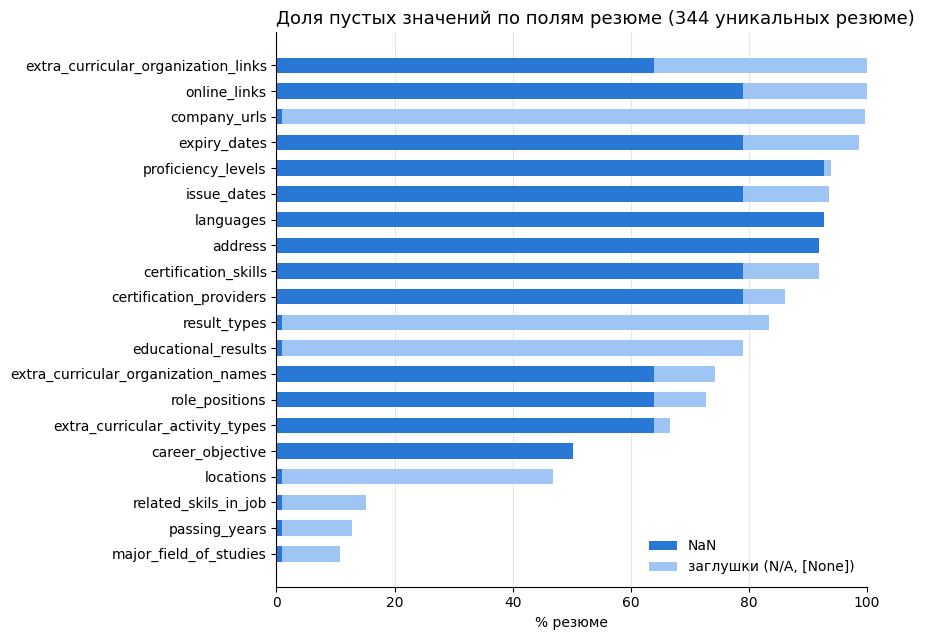

In [7]:
q = quality.sort_values("всего пусто, %").tail(20)
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(q.index, q["NaN, %"], color=BLUE, height=0.6, label="NaN")
ax.barh(q.index, q["заглушки, %"], left=q["NaN, %"], color="#9ec5f4", height=0.6,
        label="заглушки (N/A, [None])")
style_ax(ax, "Доля пустых значений по полям резюме (344 уникальных резюме)", xlabel="% резюме")
ax.legend(loc="lower right", frameon=False)
ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

In [8]:
job_cols = ["job_position_name", "educationaL_requirements", "experiencere_requirement",
            "age_requirement", "skills_required", "matched_score"]
jobs = df.drop_duplicates("job_position_name")
print("Пропуски в полях вакансий (по 28 уникальным вакансиям):")
print(jobs[job_cols].isna().sum().to_string())
print("\nВакансии без списка навыков:", jobs.loc[jobs["skills_required"].isna(), "job_position_name"].str.strip().tolist())

Пропуски в полях вакансий (по 28 уникальным вакансиям):
job_position_name            0
educationaL_requirements     0
experiencere_requirement     4
age_requirement             12
skills_required              5
matched_score                0

Вакансии без списка навыков: ['Senior Software Engineer', 'Machine Learning (ML) Engineer', 'Executive/ Sr. Executive -IT', 'Intern (Generative AI Engineering - 2D/3D Image Generation)', 'Full Stack Developer (Python,React js)']


## 4. Проверка значений: matched_score и дубликаты

matched_score: min = 0.0  max = 0.97
Вне диапазона [0, 1]: 0
Полных дубликатов строк: 0
Дубликатов резюме (одинаковый текст полей резюме): 9200 — ожидаемо, каждое резюме повторяется для каждой вакансии


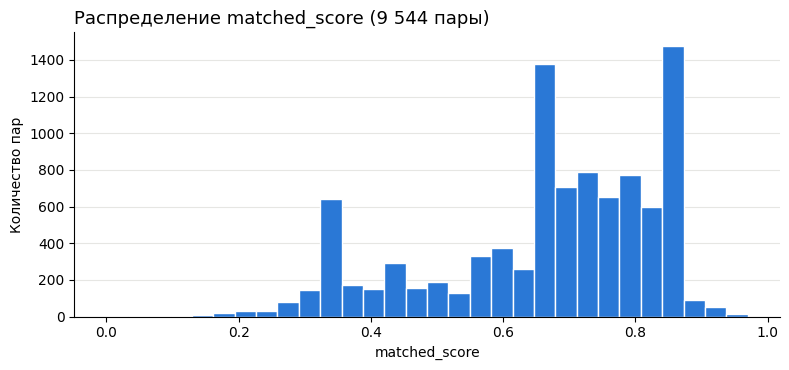

In [9]:
print("matched_score: min =", df["matched_score"].min(), " max =", df["matched_score"].max())
print("Вне диапазона [0, 1]:", ((df["matched_score"] < 0) | (df["matched_score"] > 1)).sum())
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов резюме (одинаковый текст полей резюме):", len(df) - n_resumes, "— ожидаемо, каждое резюме повторяется для каждой вакансии")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(df["matched_score"], bins=30, color=BLUE, edgecolor="white")
style_ax(ax, "Распределение matched_score (9 544 пары)", xlabel="matched_score", ylabel="Количество пар")
ax.grid(axis="y", color="#e6e6e3"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 5. Корректный разбор списков навыков

Навыки хранятся как **текст, похожий на список Python**: `"['Big Data', 'Hadoop', 'Hive']"`, а в `related_skils_in_job` — даже вложенные списки `"[['Big Data'], ['Python', 'SQL']]"`. Сравним наивный разбор (`str.split(',')`, как в EDA исходного ноутбука) и правильный (`ast.literal_eval` + разворачивание вложенных списков).

In [10]:
example = resumes["skills"].dropna().iloc[0]
print("Исходная строка:", example[:110], "...")
print("\nНаивно (split по запятой):", [s.strip() for s in example.lower().split(",")][:4])
print("Правильно (literal_eval):  ", [normalize_skill(s) for s in parse_list(example)][:4])

nested = resumes["related_skils_in_job"].dropna().iloc[1]
print("\nВложенный список:", nested[:100])
print("Развёрнутый:      ", parse_list(nested)[:6])

Исходная строка: ['Big Data', 'Hadoop', 'Hive', 'Python', 'Mapreduce', 'Spark', 'Java', 'Machine Learning', 'Cloud', 'Hdfs', 'Y ...

Наивно (split по запятой): ["['big data'", "'hadoop'", "'hive'", "'python'"]
Правильно (literal_eval):   ['big data', 'hadoop', 'hive', 'python']

Вложенный список: [['Data Analysis', 'Business Analysis', 'Machine Learning']]
Развёрнутый:       ['Data Analysis', 'Business Analysis', 'Machine Learning']


In [11]:
naive = Counter(s.strip() for raw in resumes["skills"].dropna()
                for s in raw.lower().split(","))
correct = Counter(s for raw in resumes["skills"].dropna()
                  for s in map(normalize_skill, split_skill_items(parse_list(raw))) if s)

broken = [s for s in naive if s.startswith("[") or s.endswith("]") or "'" in s]
print(f"Наивный разбор: {len(naive)} 'навыков', из них с мусором [ ] ' : {len(broken)} ({len(broken)/len(naive):.0%})")
print(f"Правильный разбор: {len(correct)} навыков")
print("\nПример: 'python' — наивно найдено", naive.get("python", 0), "раз, правильно —", correct["python"],
      "\n(при наивном разборе навык остаётся с кавычками и скобками: 'python' или ['python')")

compare = pd.DataFrame(correct.most_common(10), columns=["навык", "резюме (правильно)"])
compare["резюме (наивно)"] = compare["навык"].map(lambda s: naive.get(s, 0))
compare

Наивный разбор: 3345 'навыков', из них с мусором [ ] ' : 3126 (93%)
Правильный разбор: 3008 навыков

Пример: 'python' — наивно найдено 0 раз, правильно — 130 
(при наивном разборе навык остаётся с кавычками и скобками: 'python' или ['python')


,навык,резюме (правильно),резюме (наивно)
0,python,130,0
1,machine learning,123,0
2,excel,78,6
3,sql,63,1
4,data analysis,56,0
5,deep learning,54,0
6,natural language processing,48,0
7,java,43,0
8,c++,42,1
9,sales,39,0


**Вывод:** наивное разбиение по запятой оставляет скобки и кавычки в названиях (`"['python'"`), поэтому один навык распадается на несколько «разных» строк и частоты занижаются. Дальше во всём проекте (база данных, анализ) используется функция `parse_list()` из `database.py`, которая разбирает список через `ast.literal_eval`, разворачивает вложенные списки и делит элементы вида `"excel, word"` на отдельные навыки.

## 6. Решения по очистке и их обоснование

| Проблема | Решение | Почему |
|---|---|---|
| BOM в названии колонки `job_position_name` | удалить символ из заголовков | иначе колонка недоступна по имени |
| 9 544 строки = 344 резюме × 28 вакансий | нормализовать: резюме и вакансии по одному разу, оценки — отдельно (SQLite, `matches`) | убирает 27-кратное дублирование, позволяет делить train/test по резюме |
| `responsibilities` = копия обязанностей вакансии | не использовать как текст резюме | иначе в «резюме» попадает текст вакансии — утечка признака |
| Списки, сохранённые как текст | `ast.literal_eval` + разворачивание вложенных списков | наивный split оставляет мусор в названиях навыков |
| Заглушки `N/A`, `[None]`, `None` | считать пропусками | это не данные, а отсутствие данных |
| Регистр и варианты написания навыков (`React.js`, `reactjs`) | нижний регистр + словарь синонимов | один навык должен считаться одним |
| 5 вакансий без `skills_required` | оставить, но исключать из расчёта доли совпавших навыков | деление на ноль; при этом их тексты и оценки полезны |
| Пустые необязательные разделы резюме (сертификаты, языки) | оставить как пропуски | это нормальная особенность резюме, а не ошибка |

## 7. Объём корпуса и память

Рекомендуемый объём по требованиям — **≥ 500 тыс. строк или ≥ 200 МБ**. Наш датасет: 9 544 строки, ~17 МБ на диске, 344 уникальных резюме. Требование по объёму **не выполняется**, поэтому нужно **согласовать исключение с преподавателем** (тема 16 не входит в список заранее разрешённых исключений). Ниже показаны все приёмы работы с памятью, которые требует пункт 11, с замерами.

In [12]:
def mem_mb(frame):
    return frame.memory_usage(deep=True).sum() / 1e6

raw = pd.read_csv(CSV_PATH)
raw.columns = [c.replace("\ufeff", "").strip() for c in raw.columns]
before = mem_mb(raw)

opt = raw.copy()
low_card = [c for c in opt.columns
            if pd.api.types.is_string_dtype(opt[c]) and opt[c].nunique() < 0.5 * len(opt)]
for c in low_card:
    opt[c] = opt[c].astype("category")
opt["matched_score"] = pd.to_numeric(opt["matched_score"], downcast="float")
after = mem_mb(opt)

print(f"Колонок переведено в category: {len(low_card)} из {opt.shape[1]}")
print(f"matched_score: float64 -> {opt['matched_score'].dtype}")
print(f"\nПамять до:    {before:6.1f} МБ")
print(f"Память после: {after:6.1f} МБ  (экономия {1 - after / before:.0%})")

per_col = pd.DataFrame({
    "до, МБ": raw.memory_usage(deep=True, index=False) / 1e6,
    "после, МБ": opt.memory_usage(deep=True, index=False) / 1e6,
}).round(2).sort_values("до, МБ", ascending=False)
per_col.head(10)

Колонок переведено в category: 4 из 35
matched_score: float64 -> float32

Память до:      32.6 МБ
Память после:   25.3 МБ  (экономия 22%)


,"до, МБ","после, МБ"
skills,4.08,4.08
responsibilities.1,2.62,0.02
responsibilities,2.62,0.02
related_skils_in_job,2.25,2.25
career_objective,1.49,1.49
educationaL_requirements,1.32,0.01
positions,1.23,1.23
skills_required,1.10,1.10
professional_company_names,1.01,1.01
educational_institution_name,1.00,1.00


Почти все текстовые колонки повторяются по 28 раз (одно резюме для каждой вакансии), поэтому тип `category` хранит каждое уникальное значение один раз — экономия памяти очень большая.

### Чанковое чтение (`chunksize`)

In [13]:
def mem_of(frame):
    return frame.memory_usage(deep=True).sum() / 1e6

def full_read_stats():
    d = pd.read_csv(CSV_PATH)
    d.columns = [c.replace("\ufeff", "").strip() for c in d.columns]
    stats = d.groupby(d["job_position_name"].str.strip())["matched_score"].agg(["sum", "count"])
    return stats, mem_of(d)                  # в памяти весь файл целиком

def chunked_stats(chunksize=1000):
    total, peak = None, 0.0
    for chunk in pd.read_csv(CSV_PATH, chunksize=chunksize,
                             usecols=lambda c: c.replace("\ufeff", "").strip() in ("job_position_name", "matched_score")):
        chunk.columns = [c.replace("\ufeff", "").strip() for c in chunk.columns]
        peak = max(peak, mem_of(chunk))      # в памяти только текущий чанк
        part = chunk.groupby(chunk["job_position_name"].str.strip())["matched_score"].agg(["sum", "count"])
        total = part if total is None else total.add(part, fill_value=0)
    return total, peak

t = time.perf_counter(); full, peak_full = full_read_stats(); t_full = time.perf_counter() - t
t = time.perf_counter(); chunked, peak_chunk = chunked_stats(); t_chunk = time.perf_counter() - t

same = (full.sort_index() - chunked.sort_index()).abs().max().max() < 1e-9
print("Результаты совпадают:", same)
pd.DataFrame({
    "способ": ["весь файл сразу", "по 1 000 строк (chunksize) + нужные колонки"],
    "время, с": [round(t_full, 3), round(t_chunk, 3)],
    "данных в памяти одновременно, МБ": [round(peak_full, 2), round(peak_chunk, 3)],
})

Результаты совпадают: True


,способ,"время, с","данных в памяти одновременно, МБ"
0,весь файл сразу,0.112,32.580
1,по 1 000 строк (chunksize) + нужные колонки,0.067,0.095


Средняя оценка по вакансиям считается частями: для каждого чанка — сумма и количество, потом части складываются. Объём данных в памяти при чанковом чтении в сотни раз меньше, потому что в памяти одновременно только 1 000 строк и 2 колонки. Для файла в 200+ МБ это единственный способ не упереться в объём RAM.

### CSV vs Parquet

In [14]:
parquet_path = OUT_DIR / "resume_pairs.parquet"
opt.drop(columns=["responsibilities"]).to_parquet(parquet_path, index=False)   # дубль колонки вакансии

def read_time(fn, repeat=5):
    times = []
    for _ in range(repeat):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return sorted(times)[len(times) // 2]

csv_mb = CSV_PATH.stat().st_size / 1e6
pq_mb = parquet_path.stat().st_size / 1e6
t_csv = read_time(lambda: pd.read_csv(CSV_PATH))
t_pq = read_time(lambda: pd.read_parquet(parquet_path))
t_pq_cols = read_time(lambda: pd.read_parquet(parquet_path, columns=["job_position_name", "matched_score"]))

pd.DataFrame({
    "формат": ["CSV", "Parquet (все колонки)", "Parquet (2 колонки)"],
    "размер, МБ": [round(csv_mb, 2), round(pq_mb, 2), round(pq_mb, 2)],
    "чтение, с": [round(t_csv, 3), round(t_pq, 3), round(t_pq_cols, 3)],
})

,формат,"размер, МБ","чтение, с"
0,CSV,17.00,0.086
1,Parquet (все колонки),0.41,0.010
2,Parquet (2 колонки),0.41,0.001


Parquet хранит данные по колонкам со сжатием и сохраняет типы (включая `category`), поэтому файл меньше, читается быстрее, а нужные колонки можно прочитать без остальных. Очищенный файл `data/processed/resume_pairs.parquet` можно использовать в ноутбуке с моделями вместо CSV.

## Итоги

- Найдены и исправлены проблемы: BOM в заголовке, дублирование резюме (344 × 28), колонка-копия `responsibilities`, списки в текстовом виде, заглушки `N/A`/`[None]`, 5 вакансий без навыков.
- Правильный разбор списков (`parse_list`) используется и в базе данных, и в анализе.
- Оптимизация типов, чанковое чтение и Parquet показаны с замерами времени и памяти.
- Объём данных меньше рекомендуемого — требуется согласование исключения с преподавателем.